# OTT Streaming Content Trend Analysis — Netflix

## Objective
Explore the Netflix title catalogue to identify patterns in content type, genre, ratings, release years, and production countries. This notebook uses the supplied `netflix_titles.csv` file.

## Dataset
- Rows: 8,807 titles
- Columns: 12 original fields
- Unit of analysis: one catalogue title per row
- Important limitation: this is a static catalogue snapshot, not live Netflix viewing or popularity data. It does not contain view counts, watch time, subscriber data, or revenue.

## Questions
1. What is the balance of movies and TV shows?
2. Which genres and production countries appear most often?
3. Which content ratings are most common?
4. How has the catalogue's release-year mix changed?
5. When were titles added to the catalogue?
6. What is the typical movie duration?


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the CSV file. Keep netflix_titles.csv in the same folder as this notebook.
df = pd.read_csv("netflix_titles.csv")
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [2]:
# Basic data quality check
print("Missing values by column:")
display(df.isna().sum().to_frame("missing_values"))
print("\nDuplicate rows:", df.duplicated().sum())
print("\nContent types:")
display(df["type"].value_counts())


Missing values by column:


,missing_values
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3



Duplicate rows: 0

Content types:


type
Movie      6131
TV Show    2676
Name: count, dtype: int64

In [3]:
# Prepare analysis fields
data = df.copy()
data["date_added_dt"] = pd.to_datetime(data["date_added"], format="%B %d, %Y", errors="coerce")
data["added_year"] = data["date_added_dt"].dt.year
data["duration_num"] = pd.to_numeric(data["duration"].astype("string").str.extract(r"(\d+)")[0], errors="coerce")
data["genre_list"] = data["listed_in"].fillna("").str.split(", ")
data["country_list"] = data["country"].fillna("").str.split(", ")
data["primary_country"] = data["country"].fillna("").str.split(", ").str[0]

# Note: comma-separated genres/countries are exploded for counts.
# A title can therefore contribute to more than one genre or country.


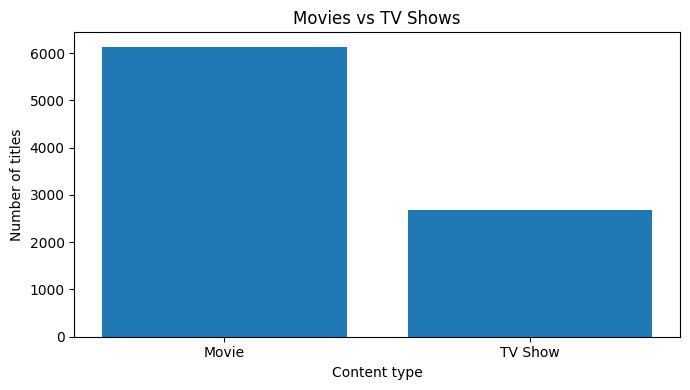

,title_count
type,
Movie,6131
TV Show,2676


In [4]:
# 1. Movies vs TV Shows
type_counts = data["type"].value_counts()
plt.figure(figsize=(7, 4))
plt.bar(type_counts.index, type_counts.values)
plt.title("Movies vs TV Shows")
plt.xlabel("Content type"); plt.ylabel("Number of titles")
plt.tight_layout(); plt.show()
display(type_counts.to_frame("title_count"))


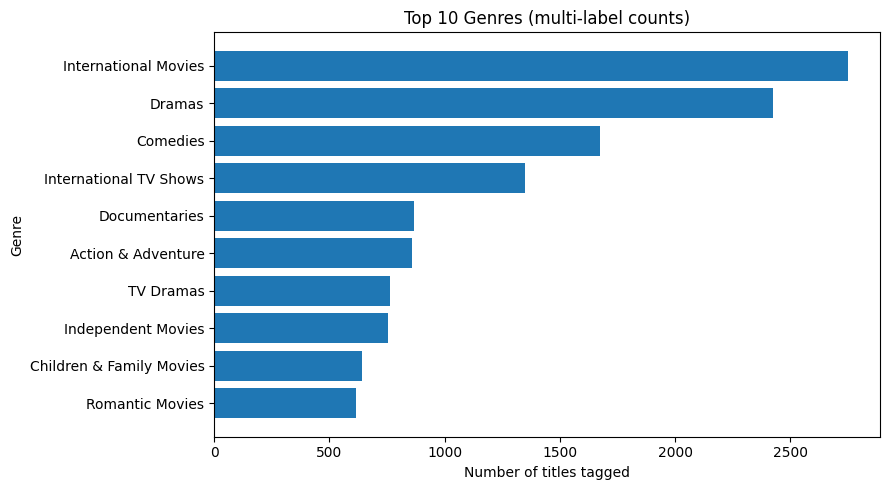

,title_count
genre_list,
International Movies,2752
Dramas,2427
Comedies,1674
International TV Shows,1351
Documentaries,869
Action & Adventure,859
TV Dramas,763
Independent Movies,756
Children & Family Movies,641


In [5]:
# 2. Top 10 genres
genre_counts = data.explode("genre_list")["genre_list"].replace("", np.nan).dropna().value_counts()
plt.figure(figsize=(9, 5))
top_genres = genre_counts.head(10).sort_values()
plt.barh(top_genres.index, top_genres.values)
plt.title("Top 10 Genres (multi-label counts)")
plt.xlabel("Number of titles tagged"); plt.ylabel("Genre")
plt.tight_layout(); plt.show()
display(genre_counts.head(10).to_frame("title_count"))


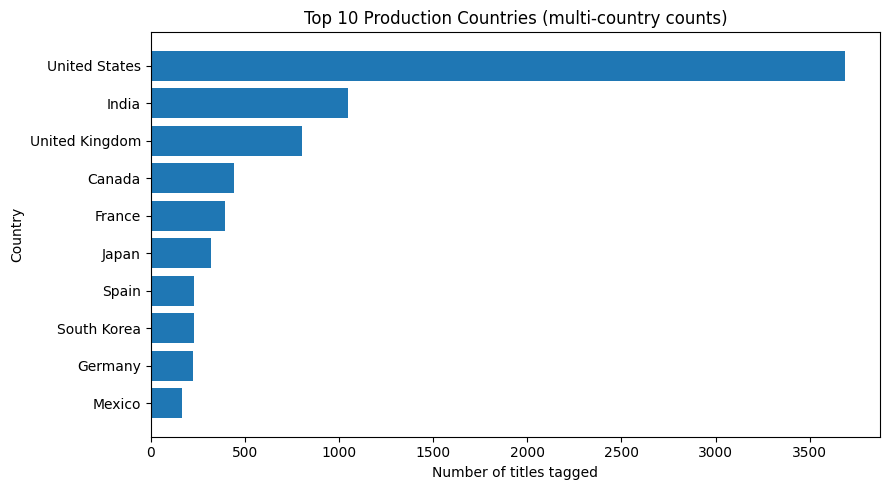

,title_count
country_list,
United States,3689
India,1046
United Kingdom,804
Canada,445
France,393
Japan,318
Spain,232
South Korea,231
Germany,226


In [6]:
# 3. Top 10 production countries
country_counts = data.explode("country_list")["country_list"].replace("", np.nan).dropna().value_counts()
plt.figure(figsize=(9, 5))
top_countries = country_counts.head(10).sort_values()
plt.barh(top_countries.index, top_countries.values)
plt.title("Top 10 Production Countries (multi-country counts)")
plt.xlabel("Number of titles tagged"); plt.ylabel("Country")
plt.tight_layout(); plt.show()
display(country_counts.head(10).to_frame("title_count"))


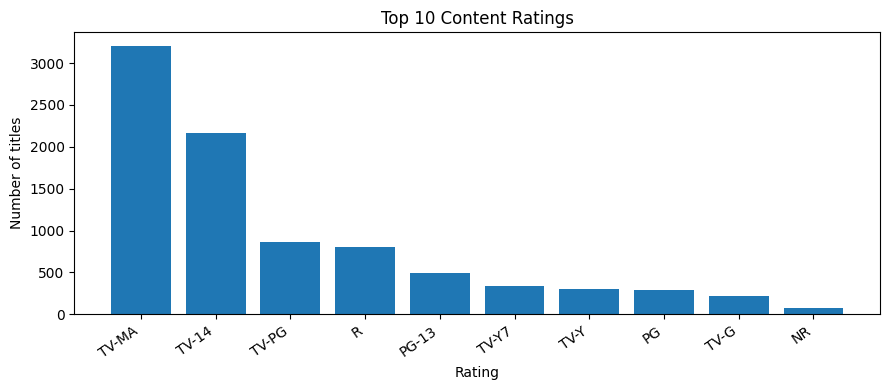

,title_count
rating,
TV-MA,3207
TV-14,2160
TV-PG,863
R,799
PG-13,490
TV-Y7,334
TV-Y,307
PG,287
TV-G,220


In [7]:
# 4. Content rating distribution
rating_counts = data["rating"].fillna("Not specified").value_counts().head(10)
plt.figure(figsize=(9, 4))
plt.bar(rating_counts.index, rating_counts.values)
plt.title("Top 10 Content Ratings")
plt.xlabel("Rating"); plt.ylabel("Number of titles")
plt.xticks(rotation=35, ha="right")
plt.tight_layout(); plt.show()
display(rating_counts.to_frame("title_count"))


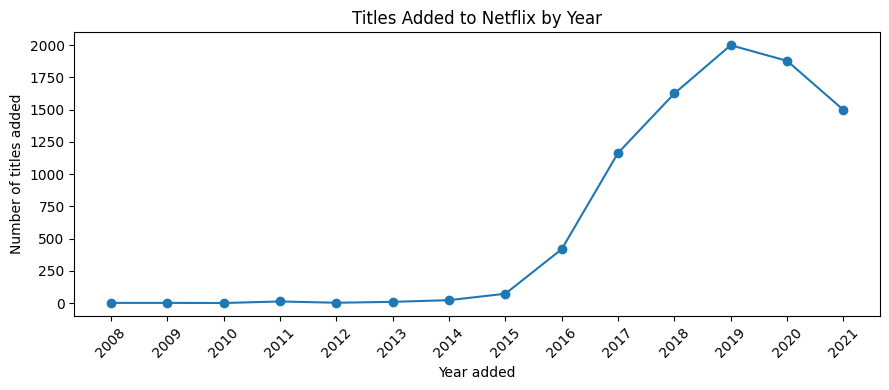

,titles_added
added_year,
2008,2
2009,2
2010,1
2011,13
2012,3
2013,10
2014,23
2015,73
2016,418


In [8]:
# 5. Titles added by year
added_counts = data["added_year"].dropna().astype(int).value_counts().sort_index()
plt.figure(figsize=(9, 4))
plt.plot(added_counts.index, added_counts.values, marker="o")
plt.title("Titles Added to Netflix by Year")
plt.xlabel("Year added"); plt.ylabel("Number of titles added")
plt.xticks(added_counts.index, rotation=45)
plt.tight_layout(); plt.show()
display(added_counts.to_frame("titles_added"))


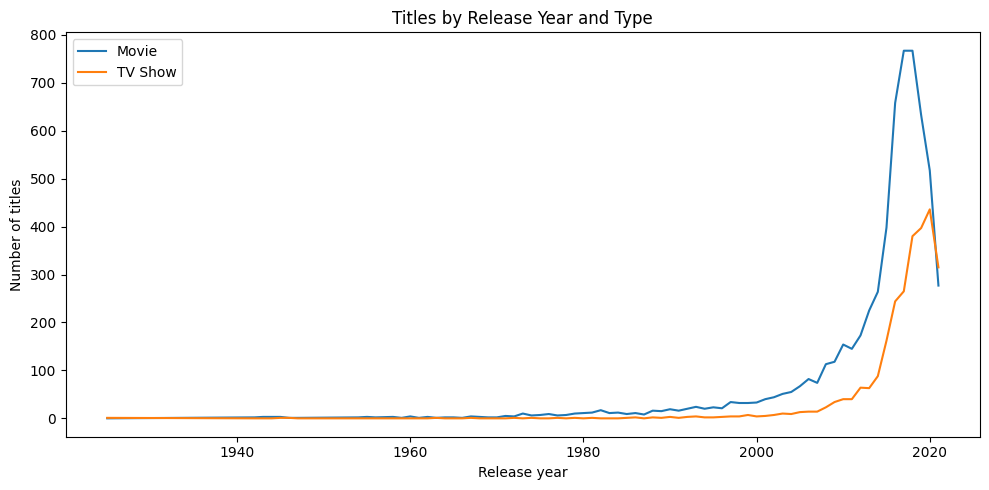

type,Movie,TV Show
release_year,,
2007,74,14
2008,113,23
2009,118,34
2010,154,40
2011,145,40
2012,173,64
2013,225,63
2014,264,88
2015,398,162


In [9]:
# 6. Titles by original release year and content type
release_type = data.groupby(["release_year", "type"]).size().unstack(fill_value=0)
plt.figure(figsize=(10, 5))
for content_type in release_type.columns:
    plt.plot(release_type.index, release_type[content_type], label=content_type)
plt.title("Titles by Release Year and Type")
plt.xlabel("Release year"); plt.ylabel("Number of titles")
plt.legend(); plt.tight_layout(); plt.show()
display(release_type.tail(15))


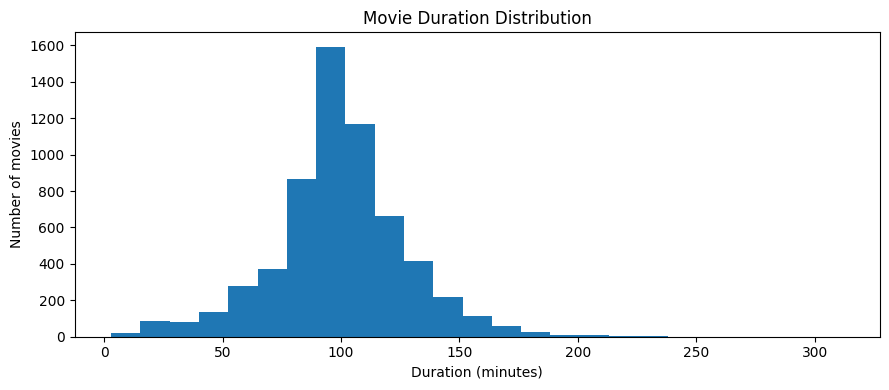

Median movie duration: 98.0 minutes
Mean movie duration: 99.6 minutes


In [10]:
# 7. Movie duration distribution (minutes)
movie_duration = data.loc[data["type"].eq("Movie"), "duration_num"].dropna()
plt.figure(figsize=(9, 4))
plt.hist(movie_duration, bins=25)
plt.title("Movie Duration Distribution")
plt.xlabel("Duration (minutes)"); plt.ylabel("Number of movies")
plt.tight_layout(); plt.show()
print("Median movie duration:", movie_duration.median(), "minutes")
print("Mean movie duration:", round(movie_duration.mean(), 1), "minutes")


In [11]:
# Key findings (based on this catalogue snapshot)
print("Movies:", int((data["type"] == "Movie").sum()))
print("TV Shows:", int((data["type"] == "TV Show").sum()))
print("Top genre:", genre_counts.index[0], "-", int(genre_counts.iloc[0]), "genre tags")
print("Top production country:", country_counts.index[0], "-", int(country_counts.iloc[0]), "country tags")
print("Most common rating:", data["rating"].mode(dropna=True).iloc[0])
print("Median movie duration:", movie_duration.median(), "minutes")


Movies: 6131
TV Shows: 2676
Top genre: International Movies - 2752 genre tags
Top production country: United States - 3689 country tags
Most common rating: TV-MA
Median movie duration: 98.0 minutes
